# Project - Airline AI Assistant

We'll now bring together what we've learned to make an AI Customer Support assistant for an Airline

In [4]:
# imports

import os
import json
from dotenv import load_dotenv
from edge_tts import communicate
from openai import OpenAI
import gradio as gr
import sqlite3

In [5]:
# Initialization

load_dotenv(override=True)

gemini_api_key = os.getenv('GOOGLE_API_KEY')
if gemini_api_key:
    print(f"Gemini API Key exists and begins {gemini_api_key[:8]}")
else:
    print("Gemini API Key not set")
    
MODEL = "gemini-3.5-flash-lite"
gemini_url = "https://generativelanguage.googleapis.com/v1beta/openai/"
gemini = OpenAI(
    api_key=gemini_api_key, base_url=gemini_url
)

DB = "prices.db"

Gemini API Key exists and begins AQ.Ab8RN


In [6]:
system_message = """
You are a helpful assistant for an Airline called FlightAI.
Give short, courteous answers, no more than 1 sentence.
Always be accurate. If you don't know the answer, say so.
"""

In [7]:
def get_ticket_price(city):
    print(f"DATABASE TOOL CALLED: Getting price for {city}", flush=True)
    with sqlite3.connect(DB) as conn:
        cursor = conn.cursor()
        cursor.execute('SELECT price FROM prices WHERE city = ?', (city.lower(),))
        result = cursor.fetchone()
        return f"Ticket price to {city} is ${result[0]}" if result else "No price data available for this city"

In [8]:
get_ticket_price("Paris")

DATABASE TOOL CALLED: Getting price for Paris


'Ticket price to Paris is $899.0'

In [9]:
price_function = {
    "name": "get_ticket_price",
    "description": "Get the price of a return ticket to the destination city.",
    "parameters": {
        "type": "object",
        "properties": {
            "destination_city": {
                "type": "string",
                "description": "The city that the customer wants to travel to",
            },
        },
        "required": ["destination_city"],
        "additionalProperties": False
    }
}
tools = [{"type": "function", "function": price_function}]
tools

[{'type': 'function',
  'function': {'name': 'get_ticket_price',
   'description': 'Get the price of a return ticket to the destination city.',
   'parameters': {'type': 'object',
    'properties': {'destination_city': {'type': 'string',
      'description': 'The city that the customer wants to travel to'}},
    'required': ['destination_city'],
    'additionalProperties': False}}}]

In [10]:

def chat(message, history):
    history = [{"role": h["role"], "content": h["content"]} for h in history]
    messages = [{"role": "system", "content": system_message}] + history + [{"role": "user", "content": message}]
    response = gemini.chat.completions.create(model=MODEL, messages=messages)
    return response.choices[0].message.content

gr.ChatInterface(fn=chat, type="messages").launch()

* Running on local URL:  http://127.0.0.1:7860
* To create a public link, set `share=True` in `launch()`.


In [8]:
def chat(message, history):
    history = [{"role":h["role"], "content":h["content"]} for h in history]
    messages = [{"role": "system", "content": system_message}] + history + [{"role": "user", "content": message}]
    response = gemini.chat.completions.create(model=MODEL, messages=messages, tools=tools)

    while response.choices[0].finish_reason=="tool_calls":
        message = response.choices[0].message
        responses = handle_tool_calls(message)
        messages.append(message)
        messages.extend(responses)
        response = gemini.chat.completions.create(model=MODEL, messages=messages, tools=tools)
    
    return response.choices[0].message.content

In [20]:
def handle_tool_calls(message):
    responses = []
    for tool_call in message.tool_calls:
        if tool_call.function.name == "get_ticket_price":
            arguments = json.loads(tool_call.function.arguments)
            city = arguments.get('destination_city')
            price_details = get_ticket_price(city)
            responses.append({
                "role": "tool",
                "content": price_details,
                "tool_call_id": tool_call.id
            })
    return responses

In [10]:
gr.ChatInterface(fn=chat, type="messages").launch()

* Running on local URL:  http://127.0.0.1:7861
* To create a public link, set `share=True` in `launch()`.


DATABASE TOOL CALLED: Getting price for London


## A bit more about what Gradio actually does:

1. Gradio constructs a frontend Svelte app based on our Python description of the UI
2. Gradio starts a server built upon the Starlette web framework listening on a free port that serves this Svelte app
3. Gradio creates backend routes for our callbacks, like chat(), which calls our functions

And of course when Gradio generates the frontend app, it ensures that the the Submit button calls the right backend route.

That's it!

It's simple, and it has a result that feels magical.

# Let's go multi-modal!!

We can use gpt-image-1-mini, the image generation model behind GPT-5, to make us some images

Let's put this in a function called artist.

### Price alert: each time I generate an image it costs about 3 cents - don't go crazy with images!

In [11]:
# Some imports for handling images

import base64
from io import BytesIO
from PIL import Image
import urllib.parse
import requests

In [12]:
def artist(city):
    prompt=f"An image representing a vacation in {city}, showing tourist spots and everything unique about {city}, in a vibrant pop-art style"

    #codificar el prompt para la URL.
    encoded_prompt = urllib.parse.quote(prompt)
    url = f"https://image.pollinations.ai/prompt/{encoded_prompt}?width=1024&height=1024&nologo=true"
    
    response = requests.get(url)
    response.raise_for_status()
    return Image.open(BytesIO(response.content))

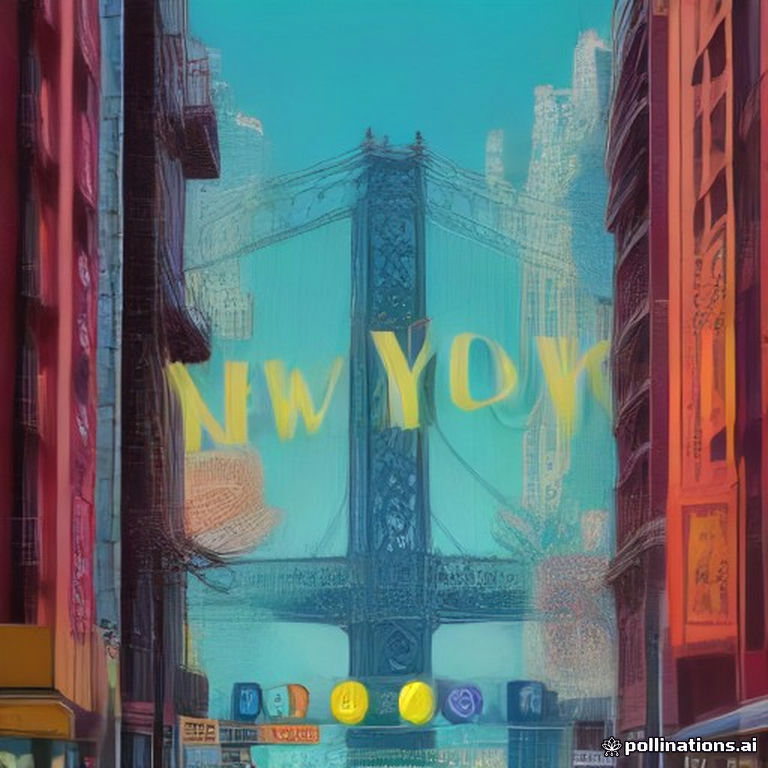

In [13]:
image = artist("New York City")
image

In [21]:
import asyncio
import edge_tts
import nest_asyncio

# Permite ejecutar tareas asincronas.

nest_asyncio.apply()

async def _edge_tts_generator(text, output_file="reply.mp3"):
    communicate = edge_tts.Communicate(text, voice="en-US-ChristopherNeural")
    await communicate.save(output_file)
    return output_file

def talker(message):
    output_file = "reply.mp3"
    asyncio.run(_edge_tts_generator(message, output_file))
    return output_file

## Let's bring this home:

1. A multi-modal AI assistant with image and audio generation
2. Tool callling with database lookup
3. A step towards an Agentic workflow


In [22]:
def chat(history):
    messages = [{"role": "system", "content": system_message}]
    for h in history:
        messages.append({"role":h["role"], "content":h["content"]})

    response = gemini.chat.completions.create(model=MODEL, messages=messages, tools=tools)
    cities = []

    while response.choices[0].finish_reason=="tool_calls":
        message_obj = response.choices[0].message
        messages.append(message_obj)

        #Ejecutar las funciones de la base de datos
        tool_responses = handle_tool_calls(message_obj)
        messages.extend(tool_responses)

        #Detectar la ciudad consultada para generar la imagen.
        for tool_call in message_obj.tool_calls:
            if tool_call.function.name in ["get_ticket_price", "set_ticket_price"]:
                args = json.loads(tool_call.function.arguments)
                city = args.get("destination_city")
                if city:
                    cities.append(city)

        response = gemini.chat.completions.create(model=MODEL, messages=messages, tools=tools)

    reply = response.choices[0].message.content
    history.append({"role": "assistant", "content": reply})

    #3. Generar audio con Talker()
    audio_path = talker(reply)

    #4. Generar imagen con artist()
    image_obj = None
    if cities:
        try:
            image_obj = artist(cities[0])
        except Exception as e:
            print(f"Error generando la imagen: {e}")
    return history, audio_path, image_obj


In [23]:
def handle_tool_calls_and_return_cities(message):
    responses = []
    cities = []
    for tool_call in message.tool_calls:
        if tool_call.function.name == "get_ticket_price":
            arguments = json.loads(tool_call.function.arguments)
            city = arguments.get('destination_city')
            cities.append(city)
            price_details = get_ticket_price(city)
            responses.append({
                "role": "tool",
                "content": price_details,
                "tool_call_id": tool_call.id
            })
    return responses, cities

## The 3 types of Gradio UI

`gr.Interface` is for standard, simple UIs

`gr.ChatInterface` is for standard ChatBot UIs

`gr.Blocks` is for custom UIs where you control the components and the callbacks

In [24]:
# Callbacks (along with the chat() function above)

def put_message_in_chatbot(message, history):
        return "", history + [{"role":"user", "content":message}]

# UI definition

with gr.Blocks(title="FlightAI Multimodal Assistant") as ui:
    gr.Markdown("## ✈️ FlightAI - Asistente Multimodal de Viajes")

    with gr.Row():
        with gr.Column(scale=2):
            chatbot = gr.Chatbot(label="Chat", height=500, type="messages")
        with gr.Column(scale=1):
            image_output = gr.Image(label="Destino Turístico", height=500)

    with gr.Row():
        audio_output = gr.Audio(label="Respuesta de Voz", autoplay=True)

    with gr.Row():
        msg_input = gr.Textbox(
            label="Tu consulta",
            placeholder="Pregunta sobre precios a París, Londres o Tokio...",
            scale=4
        )
        submit_btn = gr.Button("Enviar", variant="primary", scale=1)

    # Función intermediaria para añadir la pregunta del usuario al chatbot
    def user_turn(user_message, history):
        if not user_message.strip():
            return "", history
        history = history or []
        history.append({"role": "user", "content": user_message})
        return "", history

    # Flujo de ejecución al enviar:
    # 1. Pone el mensaje del usuario en el chatbox
    # 2. Llama a chat() que consulta Gemini, ejecuta tools, crea la imagen y el audio
    msg_input.submit(
        user_turn,
        [msg_input, chatbot],
        [msg_input, chatbot]
    ).then(
        chat,
        [chatbot],
        [chatbot, audio_output, image_output]
    )

    submit_btn.click(
        user_turn,
        [msg_input, chatbot],
        [msg_input, chatbot]
    ).then(
        chat,
        [chatbot],
        [chatbot, audio_output, image_output]
    )

ui.launch()

* Running on local URL:  http://127.0.0.1:7863
* To create a public link, set `share=True` in `launch()`.


DATABASE TOOL CALLED: Getting price for Argentina
Error generando la imagen: 503 Server Error: Service Unavailable for url: https://image.pollinations.ai/prompt/An%20image%20representing%20a%20vacation%20in%20Argentina%2C%20showing%20tourist%20spots%20and%20everything%20unique%20about%20Argentina%2C%20in%20a%20vibrant%20pop-art%20style?width=1024&height=1024&nologo=true
DATABASE TOOL CALLED: Getting price for New York
Error generando la imagen: 402 Client Error: Payment Required for url: https://image.pollinations.ai/prompt/An%20image%20representing%20a%20vacation%20in%20New%20York%2C%20showing%20tourist%20spots%20and%20everything%20unique%20about%20New%20York%2C%20in%20a%20vibrant%20pop-art%20style?width=1024&height=1024&nologo=true


# Exercises and Business Applications

Add in more tools - perhaps to simulate actually booking a flight. A student has done this and provided their example in the community contributions folder.

Next: take this and apply it to your business. Make a multi-modal AI assistant with tools that could carry out an activity for your work. A customer support assistant? New employee onboarding assistant? So many possibilities! Also, see the week2 end of week Exercise in the separate Notebook.

<table style="margin: 0; text-align: left;">
    <tr>
        <td style="width: 150px; height: 150px; vertical-align: middle;">
            <img src="../assets/thankyou.jpg" width="150" height="150" style="display: block;" />
        </td>
        <td>
            <h2 style="color:#090;">I have a special request for you</h2>
            <span style="color:#090;">
                My editor tells me that it makes a HUGE difference when students rate this course on Udemy - it's one of the main ways that Udemy decides whether to show it to others. If you're able to take a minute to rate this, I'd be so very grateful! And regardless - always please reach out to me at ed@edwarddonner.com if I can help at any point.
            </span>
        </td>
    </tr>
</table>